# Tutorial 8: Measuring the impact of a retracted paper

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melhzy/pubmed-stream/blob/main/tutorials/08_retraction_impact.ipynb) Run it in your browser with nothing to install, or on your own computer: [how to run the tutorials](guides/setup.md).

In 2006, *Nature* published **"A specific amyloid-β protein assembly in the brain impairs memory"** (Lesné and colleagues, [PMID 16541076](https://pubmed.ncbi.nlm.nih.gov/16541076/)). It reported **Aβ\*56**, an assembly of amyloid-β that impaired memory in mice, and it became one of the most cited papers in Alzheimer's disease research. In July 2022 an investigation in *Science* raised concerns about manipulated images in it, and *Nature* added an editor's note. In June 2024 the paper was **retracted**, with all authors except the first agreeing ([retraction notice, PMID 38914864](https://pubmed.ncbi.nlm.nih.gov/38914864/)).

A retraction removes a paper from the record, but not the papers built on it. This tutorial measures how far the paper reached, step by step:

1. **The paper** and the notices PubMed links to it.
2. **How far it reached**: the papers that cite it (its neighbors), and the papers that cite those (its neighbors' neighbors).
3. **When it was cited**, before and after the doubts and the retraction.
4. **How it was cited**: the sentence in which each citing paper cites it, read from the full text.
5. **Who cites it after the retraction**, and whether they say so.
6. **Retracted papers that cite it.**
7. **Where its influence travelled**: the citing papers that carried it furthest.
8. **Compared with its neighbors**: the papers PubMed finds most similar.
9. **A knowledge graph** of all of it, to explore in Obsidian.

It is an example of **citation impact analysis**: the same notebook measures any paper, retracted or not, if you change the settings. Words such as MeSH, PMC or stub are explained in the [glossary](guides/glossary.md).

**Time:** about 15 minutes. Most of it is spent downloading the full text of the citing papers, about 100 MB; a second run reuses the files and is faster, and a free NCBI API key makes everything about three times faster.

## Your settings

This is the only cell you need to edit. To study another paper, change the PubMed ID, its DOI, a few words of its title, and the words that name its specific finding.

In [1]:
SEED = "16541076"                 # PubMed ID of the paper: A specific amyloid-beta protein assembly in the brain impairs memory
SEED_DOI = "10.1038/nature04533"  # its DOI, to find it in reference lists
TITLE_WORDS = "specific amyloid"  # a few words of its title, for references without a DOI
FINDING = "Aβ*56"                 # a short name for its specific finding, for the charts
FINDING_WORDS = ["Aβ*56", "Abeta*56", "A beta*56", "Aβ56", "Abeta56", "56-kDa", "56 kDa"]   # how authors write it
DOUBTS_PUBLIC = 2022              # the year doubts about the paper became public
RETRACTED = 2024                  # the year it was retracted
SECOND_HOP_SEEDS = 10             # citing papers whose own neighborhoods join the knowledge graph
NCBI_API_KEY = ""   # optional: paste your free NCBI key between the quotes to run about three times faster

In [2]:
# Setup: run this cell as it is. In Google Colab it first fetches the tutorial files.
import os
import re
import subprocess
import sys

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/pubmed-stream"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/melhzy/pubmed-stream.git", "/content/pubmed-stream"], check=True)
    sys.path.insert(0, "/content/pubmed-stream/tutorials")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tutorial_utils as tu

tu.setup("retraction_impact", api_key=NCBI_API_KEY)
tu.style()
pd.set_option("display.max_colwidth", 200)

import citation_impact as ci
from pubmed_stream import create_kg, download_neighborhood, get_neighborhood

finding = re.compile("|".join(re.escape(w) for w in FINDING_WORDS), re.I)
KINDS = [ci.KINDS[0], f"Names {FINDING}", ci.KINDS[2], ci.KINDS[3]]
KIND_COLOURS = dict(zip(KINDS, [tu.ORANGE, tu.BLUE, tu.AQUA, tu.GREY]))

## 1. The paper and its notices

`get_neighborhood` fetches the paper with **every** paper PubMed links to it: here up to 5,000 citing papers instead of the usual 100. PubMed also links the notices published about a paper: its retraction, corrections and comments.

In [3]:
hood = get_neighborhood(SEED, max_per_relation=5000)
seed = hood.seed
print(f"{seed.title}\n{', '.join(seed.authors)}\n{seed.journal}, {seed.year}. Retracted: {seed.is_retracted}")
print("Publication types:", ", ".join(seed.pub_types))
pd.DataFrame(ci.corrections(SEED))

A specific amyloid-beta protein assembly in the brain impairs memory.
Lesné Sylvain, Koh Ming Teng, Kotilinek Linda, Kayed Rakez, Glabe Charles G, Yang Austin, Gallagher Michela, Ashe Karen H
Nature, 2006. Retracted: True
Publication types: Journal Article, Research Support, N.I.H., Extramural, Retracted Publication


,type,pmid,source
0,Comment In,16541054,Nature. 2006 Mar 16;440(7082):284-5. doi: 10.1038/440284a.
1,Retraction In,38914864,Nature. 2024 Jul;631(8019):240. doi: 10.1038/s41586-024-07691-8.


## 2. How far did it reach?

The **neighbors** are the papers that cite it. The **neighbors' neighbors** are the papers that cite one of those: they may never cite the retracted paper themselves, but they build on work that does. PubMed answers both questions with its citation links, a hundred papers per request, so this cell takes two or three minutes.

To put the numbers in proportion, the last two lines count Alzheimer's disease papers: those PubMed indexes under the MeSH heading *Alzheimer Disease* since the paper appeared, and how many of them are within these two steps.

In [4]:
hop1 = {a.pmid for a in hood.cited_by}
citers = ci.citers_of(sorted(hop1))
hop2 = set().union(*citers.values()) - hop1 - {SEED}

first_year = int(seed.year)
ad = f"alzheimer disease[mh] AND {first_year}:3000[dp]"
ad_total = ci.pubmed_count(ad)
ad_near = ci.count_matching(hop1 | hop2, {"ad": "alzheimer disease[mh]"})["ad"]
reach = pd.DataFrame([
    {"step": "Cite the paper (neighbors)", "papers": len(hop1)},
    {"step": "Cite a paper that cites it, but not the paper (neighbors' neighbors)", "papers": len(hop2)},
    {"step": f"Alzheimer's disease papers in PubMed since {first_year}", "papers": ad_total},
    {"step": "... of which within these two steps", "papers": ad_near},
]).set_index("step")
reach

,papers
step,
Cite the paper (neighbors),1240
"Cite a paper that cites it, but not the paper (neighbors' neighbors)",44921
Alzheimer's disease papers in PubMed since 2006,107302
... of which within these two steps,15039


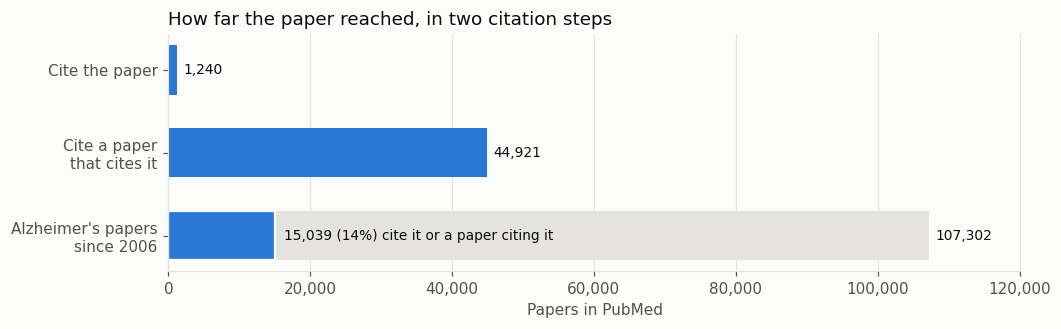

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.8))
labels = ["Cite the paper", "Cite a paper\nthat cites it", f"Alzheimer's papers\nsince {first_year}"]
y = [2, 1, 0]
ax.barh(y[:2], [len(hop1), len(hop2)], color=tu.BLUE, height=0.6)
ax.barh(0, ad_total, color=tu.GRID, height=0.6)
ax.barh(0, ad_near, color=tu.BLUE, height=0.6, edgecolor=tu.SURFACE, lw=1.5)
for value, row in [(len(hop1), 2), (len(hop2), 1), (ad_total, 0)]:
    ax.annotate(f"{value:,}", (value, row), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.annotate(f"{ad_near:,} ({ad_near / ad_total:.0%}) cite it or a paper citing it", (ad_near, 0), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color=tu.INK)
ax.set_yticks(y, labels)
tu.gridlines(ax, "x")
ax.set_xlim(0, ad_total * 1.12)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Papers in PubMed")
ax.set_title("How far the paper reached, in two citation steps")
plt.show()

Each step multiplies the reach. Most of the second step is not about Aβ\*56 at all: a paper that cites a broad review of amyloid-β, which happens to cite the retracted paper, counts too. The second step is therefore an upper bound on influence, not a measure of harm. Section 4 narrows it down by reading how each paper cites the retracted one.

## 3. When was it cited?

The bars count the citing papers per year, split into reviews and original research; the dashed lines mark the year doubts became public and the year of retraction. The lower panel shows the neighbors' neighbors, the second step.

PubMed's citation links come from articles deposited in PubMed Central, so they count fewer citations than Google Scholar or Web of Science, and the last year or two are incomplete while new articles are processed.

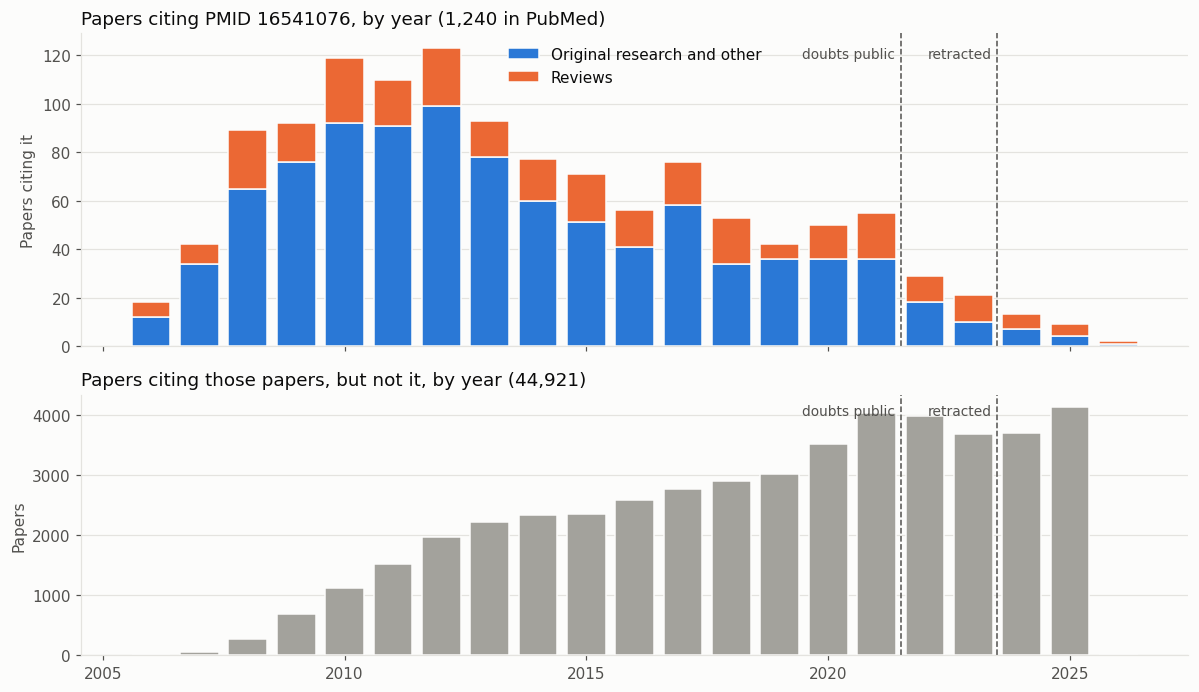

In [6]:
cited_by = pd.DataFrame([{"pmid": a.pmid, "year": int(a.year), "review": a.is_review, "retracted": a.is_retracted,
                          "nih_funded": a.nih_funded, "pmcid": a.pmcid, "title": a.title, "authors": a.authors}
                         for a in hood.cited_by if a.year and a.year.isdigit()])
last_year = int(cited_by["year"].max())
span = np.arange(first_year, last_year + 1)
per_year = cited_by.groupby(["year", "review"]).size().unstack(fill_value=0).reindex(span, fill_value=0)
hop2_years = ci.count_by_year(hop2, first_year, last_year)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
top.bar(span, per_year.get(False, 0), color=tu.BLUE, edgecolor=tu.SURFACE, lw=1, label="Original research and other")
top.bar(span, per_year.get(True, 0), bottom=per_year.get(False, 0), color=tu.ORANGE, edgecolor=tu.SURFACE, lw=1,
        label="Reviews")
top.set_ylabel("Papers citing it")
top.legend(loc="upper center")
top.set_title(f"Papers citing PMID {SEED}, by year ({len(cited_by):,} in PubMed)")
bars = bottom.bar(span, [hop2_years[y] for y in span], color=tu.GREY, edgecolor=tu.SURFACE, lw=1)
bottom.set_ylabel("Papers")
bottom.set_title(f"Papers citing those papers, but not it, by year ({len(hop2):,})")
for ax in (top, bottom):
    tu.gridlines(ax)
    for year, label in [(DOUBTS_PUBLIC, "doubts public"), (RETRACTED, "retracted")]:
        ax.axvline(year - 0.5, color=tu.INK_2, lw=1, ls="--")
        ax.annotate(label, (year - 0.5, ax.get_ylim()[1] * 0.92), xytext=(-4, 0), textcoords="offset points",
                    ha="right", fontsize=9, color=tu.INK_2)
plt.tight_layout()
plt.show()

In [7]:
peak = per_year.sum(axis=1)
print(f"Most citations in one year: {peak.max()} in {peak.idxmax()}")
print(f"Citing papers from {DOUBTS_PUBLIC} on: {int(peak[peak.index >= DOUBTS_PUBLIC].sum())}, "
      f"from {RETRACTED} on: {int(peak[peak.index >= RETRACTED].sum())}")
print(f"Reviews: {cited_by['review'].sum()} of {len(cited_by)} ({cited_by['review'].mean():.0%}); "
      f"NIH-funded: {cited_by['nih_funded'].mean():.0%}")

Most citations in one year: 123 in 2012
Citing papers from 2022 on: 74, from 2024 on: 24
Reviews: 301 of 1240 (24%); NIH-funded: 52%


## 4. How was it cited?

A citation count says nothing about **why** a paper was cited. Was it the evidence for a key step in the argument, one of many references for a general statement, or an example of a problem? The full text answers that.

The next cell downloads the full text of every citing paper in PubMed Central, as XML. In XML each citation is marked, so `ci.citation_contexts` can find the exact sentence that cites the paper, even inside a range such as [10–14]. `ci.classify` then sorts each citing paper by its sentences, in this order:

| Kind | The sentence citing the paper... | Colour |
|---|---|---|
| **Discusses the retraction or doubts** | mentions the retraction, manipulated data or images, fabrication, an editor's note, concerns about the paper, or a failure to reproduce it | orange |
| **Names Aβ\*56** | names the specific finding, with one of `FINDING_WORDS` | blue |
| **Cites it in general** | supports a general statement, such as "soluble oligomers impair memory" | aqua |
| **No full text, or citation not found** | was not readable: the paper is not in PubMed Central, its publisher withholds the full text, or the citing sentence could not be found, for instance because it is in a table | grey |

The classification uses keywords, so it makes mistakes: read the examples below before you trust the counts.

In [8]:
with tu.quiet():
    stats = download_neighborhood(hood, output_dir="fulltext", fmt="xml", include_text=False)
print(f"Full text: {stats.successful} downloaded now, {stats.skipped} already here, {stats.failed} not available")

contexts = ci.citation_contexts(stats.output_dir, SEED, SEED_DOI, TITLE_WORDS, finding=finding)
by_pmid = {c["pmid"]: c for c in contexts.values() if c["pmid"]}

def kind_of(pmid):
    kind = ci.classify(by_pmid.get(pmid, {}).get("sentences", []), finding)
    return f"Names {FINDING}" if kind == ci.KINDS[1] else kind

cited_by["kind"] = cited_by["pmid"].map(kind_of)
cited_by["sentence"] = cited_by["pmid"].map(lambda p: " … ".join(by_pmid.get(p, {}).get("sentences", [])))
cited_by["mentions"] = cited_by["pmid"].map(lambda p: by_pmid.get(p, {}).get("mentions"))
no_text = (~cited_by["pmid"].isin(list(by_pmid))).sum()
print(f"Not read: {no_text} citing papers have no full text here, and in "
      f"{(cited_by['kind'] == KINDS[3]).sum() - no_text} more the citing sentence was not found")
cited_by["kind"].value_counts().reindex(KINDS, fill_value=0).to_frame("citing papers")

Full text: 832 downloaded now, 0 already here, 375 not available


Not read: 440 citing papers have no full text here, and in 44 more the citing sentence was not found


,citing papers
kind,
Discusses the retraction or doubts,9
Names Aβ*56,157
Cites it in general,590
"No full text, or citation not found",484


How the kinds changed over time. Each bar is one period, and the segments are the share of its citing papers; the number at the end of each bar is how many papers it holds.

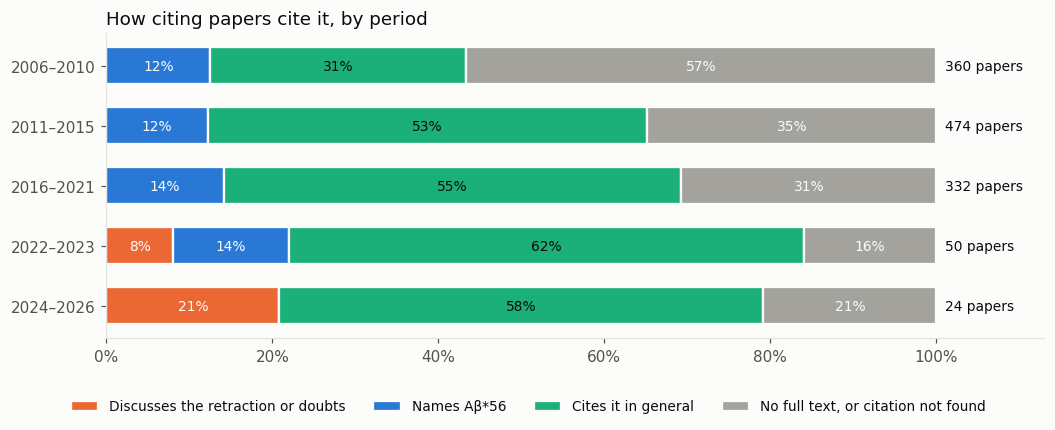

In [9]:
edges = [first_year, 2011, 2016, DOUBTS_PUBLIC, RETRACTED, last_year + 1]
names = [f"{a}–{b - 1}" if b - 1 > a else str(a) for a, b in zip(edges, edges[1:])]
cited_by["period"] = pd.cut(cited_by["year"], edges, right=False, labels=names)
shares = cited_by.groupby("period", observed=False)["kind"].value_counts(normalize=True).unstack(fill_value=0)
shares = shares.reindex(columns=KINDS, fill_value=0)
sizes = cited_by["period"].value_counts().reindex(names)

fig, ax = plt.subplots(figsize=(11, 3.6))
left = np.zeros(len(names))
for kind in KINDS:
    ax.barh(names, shares[kind], left=left, color=KIND_COLOURS[kind], edgecolor=tu.SURFACE, lw=1.5, height=0.62,
            label=kind)
    for i, (start, share) in enumerate(zip(left, shares[kind])):
        if share >= 0.06:
            ax.annotate(f"{share:.0%}", (start + share / 2, i), ha="center", va="center", fontsize=9,
                        color=tu.SURFACE if kind != ci.KINDS[2] else tu.INK)
    left += shares[kind].values
for i, n in enumerate(sizes):
    ax.annotate(f"{n} papers", (1, i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.13)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=4, fontsize=9)
ax.set_title("How citing papers cite it, by period")
plt.show()

Read a few sentences of each kind. They show what the paper was used for, and whether the classification is right. **⟦CITE⟧** marks the place where the sentence cites the retracted paper; the other numbers are its other references.

In [10]:
examples = (cited_by[cited_by["sentence"] != ""].sort_values("year", ascending=False)
            .groupby("kind").head(3).sort_values(["kind", "year"]))
examples[["kind", "year", "pmid", "sentence"]].assign(sentence=examples["sentence"].map(lambda s: tu.short(s, 300)))

,kind,year,pmid,sentence
2,Cites it in general,2025,41624198,"The amyloid-beta (Aβ) hypothesis proposes that soluble Aβ oligomers (SO-Aβ) are major drivers of synaptic dysfunction and neuronal injury (⟦CITE⟧, 3)."
11,Cites it in general,2025,39422790,"However, it is unclear whether AD pathogenesis is driven by non-fibrillar Aβ multimers or amyloid plaques [97, ⟦CITE⟧]."
4,Cites it in general,2025,40413393,"In an extreme example, post-publication peer review and “sleuthing” successfully identified serious errors in Alzheimer’s disease research [⟦CITE⟧, 6], but more than a decade after the original pu..."
14,Discusses the retraction or doubts,2024,39121130,"The hypothesis was that a specific amyloid-β (Aβ) protein assembly, Aβ*56, blocks memory.⟦CITE⟧ … As a result, the article was retracted by Nature on March 16, 2024 and most of the authors agreed ..."
7,Discusses the retraction or doubts,2025,39996369,"Candidates have included dimers,51 dodecamers52 (note: the initial 2006 study identifying dodecamers⟦CITE⟧ was recently retracted due to data manipulation), and even a heterogeneous “oligomeric so..."
3,Discusses the retraction or doubts,2025,41227148,"Chistian Piller, journalist at e-Science, documented several examples of this scientific pressure: the retraction of an influential article published in 2006 in Nature [⟦CITE⟧,96] about the role o..."
58,Names Aβ*56,2022,35557606,"Size exclusion chromatography (SEC) analysis of these AβO solutions revealed a predominant peak eluting shortly before the 43 kDa standard, likely corresponding to the 56 kDa dodecamer identified ..."
55,Names Aβ*56,2022,35885050,"Three oligomeric structures amyloid-β trimers, Aβ*56 and amyloid-β dimers—have been identified in AD mouse models and humans [40,⟦CITE⟧]."
33,Names Aβ*56,2023,37216514,Concentrations of Aβ trimers are elevated in cognitively normal adults who are at risk for Alzheimer’s disease (⟦CITE⟧). … Aβ trimers appear to be the building blocks of the putative dodecamer of ...


In [11]:
found = cited_by[cited_by["kind"] != ci.KINDS[3]]
never = (found["mentions"] == 0).sum()
print(f"Citing papers whose citing sentence was found: {len(found)} of {len(cited_by)}")
print(f"Of these, {never} ({never / len(found):.0%}) never mention {FINDING} anywhere in their text: "
      "they cite the paper for a broader claim.")

Citing papers whose citing sentence was found: 756 of 1240
Of these, 578 (76%) never mention Aβ*56 anywhere in their text: they cite the paper for a broader claim.


## 5. Cited after the doubts and the retraction

These are the papers that cite it from the year doubts became public onwards, newest first. A citation after a retraction is not always an error: a paper may cite it to discuss the retraction. The *kind* column tells the two apart.

In [12]:
late = cited_by[cited_by["year"] >= DOUBTS_PUBLIC].sort_values("year", ascending=False)
print(late["kind"].value_counts().reindex(KINDS, fill_value=0).to_string())
late[["year", "pmid", "kind", "title"]].assign(title=late["title"].map(lambda t: tu.short(t, 90)))

kind
Discusses the retraction or doubts      9
Names Aβ*56                             7
Cites it in general                    45
No full text, or citation not found    13


,year,pmid,kind,title
0,2026,42624989,"No full text, or citation not found",Targeting soluble misfolded oligomers in anti-amyloid research.
1,2026,42066286,"No full text, or citation not found",Performance of AI Tools in Citing Retracted Literature : Content Analysis.
2,2025,41624198,Cites it in general,Unraveling the neuroprotective mechanisms of elephant black garlic extract against beta a…
3,2025,41227148,Discusses the retraction or doubts,"Alzheimer Syndrome or Age-Related Dementia-History, Therapy and Prevention."
4,2025,40413393,Cites it in general,"""Non-Markovian"" and ""directional"" errors inhibit scientific self-correction and can lead…"
...,...,...,...,...
74,2022,35038191,Cites it in general,The amyloid concentric β-barrel hypothesis: Models of amyloid beta 42 oligomers and annul…
76,2022,34896392,Names Aβ*56,Aptamers targeting amyloidogenic proteins and their emerging role in neurodegenerative di…
79,2022,34878720,Cites it in general,Rational Design of a Cu Chelator That Mitigates Cu-Induced ROS Production by Amyloid Beta.
81,2022,34810230,"No full text, or citation not found",Presenilin/γ-Secretase Activity Is Located in Acidic Compartments of Live Neurons.


## 6. Retracted papers that cite it

Retractions cluster: when one paper falls, papers by the same authors, or built on the same data, are often examined too. PubMed flags each citing paper that has itself been retracted. The last column lists the authors it shares with the retracted paper, matched by last name and first initial, because PubMed writes "Lesné Sylvain" in one record and "Lesné Sylvain E" in another.

In [13]:
def person(name):
    parts = name.split()
    return (parts[0], parts[1][:1]) if len(parts) > 1 else (name, "")

seed_people = {person(n) for n in seed.authors}
retracted = cited_by[cited_by["retracted"]].copy()
retracted["shared_authors"] = retracted["authors"].map(lambda names: ", ".join(n for n in names if person(n) in seed_people))
retracted["their_citers"] = retracted["pmid"].map(lambda p: len(citers.get(p, [])))
retracted[["year", "pmid", "title", "kind", "their_citers", "shared_authors"]].sort_values("year")

,year,pmid,title,kind,their_citers,shared_authors
915,2010,20655472,SIRT1 suppresses beta-amyloid production by activating the alpha-secretase gene ADAM10.,Cites it in general,209,
981,2011,20031278,Cognitive effects of cell-derived and synthetically derived Aβ oligomers.,Names Aβ*56,71,"Lesné Sylvain, Ashe Karen H"
682,2012,22836259,Soluble α-synuclein is a novel modulator of Alzheimer's disease pathophysiology.,"No full text, or citation not found",79,Lesné Sylvain E
651,2012,23175838,The complex PrP(c)-Fyn couples human oligomeric Aβ with pathological tau changes in Alzheimer's disease.,"No full text, or citation not found",174,Lesné Sylvain E
316,2017,28487416,The amyloid-β oligomer Aβ*56 induces specific alterations in neuronal signaling that lead to tau phosphorylation and aggregation.,Names Aβ*56,60,Lesné Sylvain E
163,2020,32246090,In situ structural characterization of early amyloid aggregates in Alzheimer's disease transgenic mice and Octodon degus.,Names Aβ*56,3,


## 7. Where did its influence travel?

Some citing papers carried the paper much further than others: a widely cited review that repeats its finding reaches thousands of readers. The chart ranks the citing papers by how many papers cite **them**, coloured by how they cite the retracted paper.

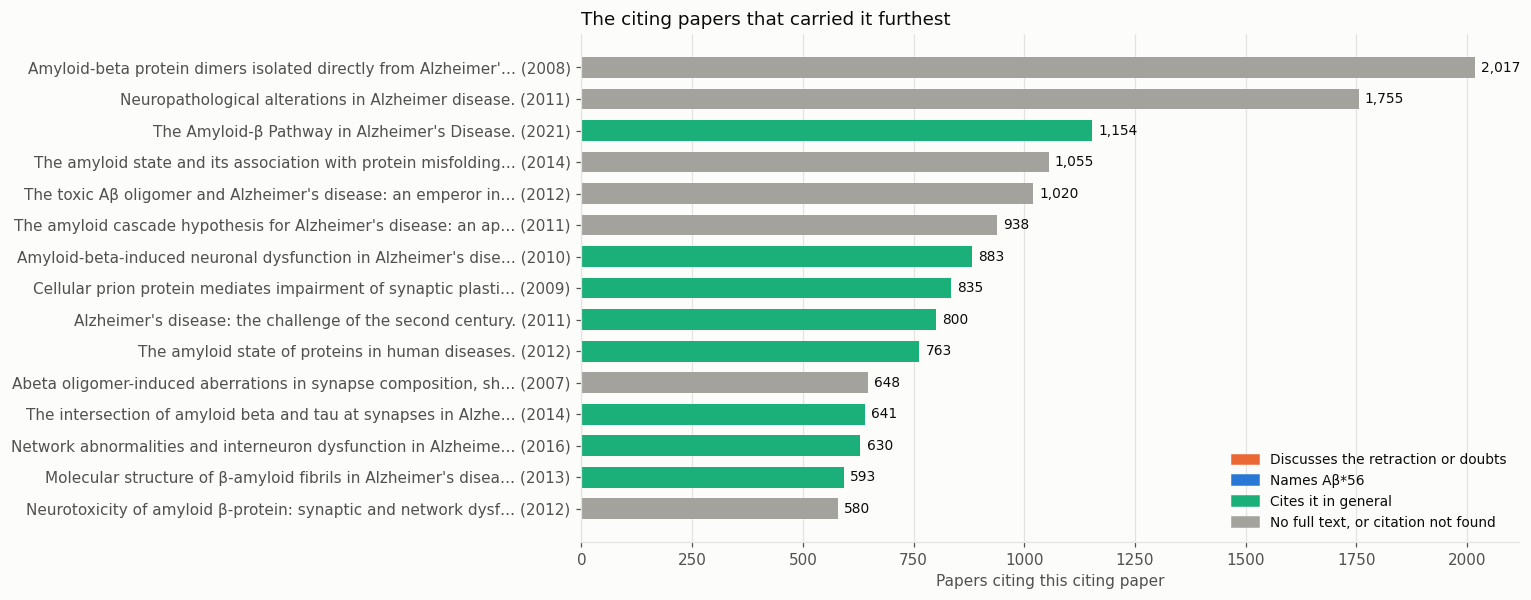

In [14]:
cited_by["their_citers"] = cited_by["pmid"].map(lambda p: len(citers.get(p, [])))
top = cited_by.nlargest(15, "their_citers").iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh([f"{tu.short(t, 62)} ({y})" for t, y in zip(top["title"], top["year"])], top["their_citers"],
               color=[KIND_COLOURS[k] for k in top["kind"]], height=0.66)
tu.bar_labels(ax, bars, "{:,.0f}", horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Papers citing this citing paper")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOURS.values()], labels=KINDS,
          loc="lower right", fontsize=9)
ax.set_title("The citing papers that carried it furthest")
plt.show()

The same question for all the second-step papers: how many are reached through each kind of citation? A paper reached through a citing paper that **names Aβ\*56** is downstream of the specific finding; one reached only through general citations is downstream of the broader idea.

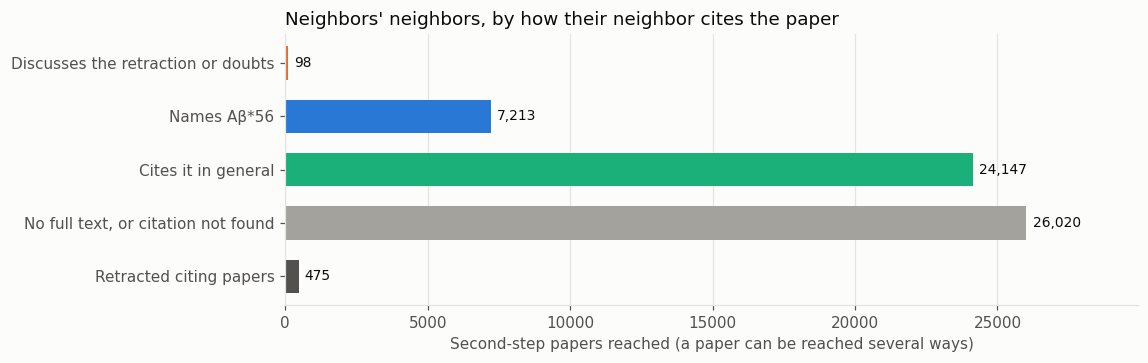

In [15]:
reached = {kind: set().union(*[set(citers.get(p, [])) for p in cited_by.loc[cited_by["kind"] == kind, "pmid"]]) - hop1 - {SEED}
           for kind in KINDS}
reached["Retracted citing papers"] = set().union(*[set(citers.get(p, [])) for p in retracted["pmid"]]) - hop1 - {SEED}
fig, ax = plt.subplots(figsize=(10, 3.2))
labels = list(reached)
bars = ax.barh(labels[::-1], [len(reached[k]) for k in labels][::-1],
               color=[KIND_COLOURS.get(k, tu.INK_2) for k in labels][::-1], height=0.62)
tu.bar_labels(ax, bars, "{:,.0f}", horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlim(0, max(len(v) for v in reached.values()) * 1.15)
ax.set_xlabel("Second-step papers reached (a paper can be reached several ways)")
ax.set_title("Neighbors' neighbors, by how their neighbor cites the paper")
plt.show()

## 8. Compared with its neighbors

Is that much reach unusual? The papers PubMed finds most **similar** to the retracted one are a fair comparison: same topic, similar methods. Each dot is one similar paper, placed by its year and by how many papers cite it; the retracted paper is the large orange dot. Citations are on a log scale, because they range from a handful to over a thousand.

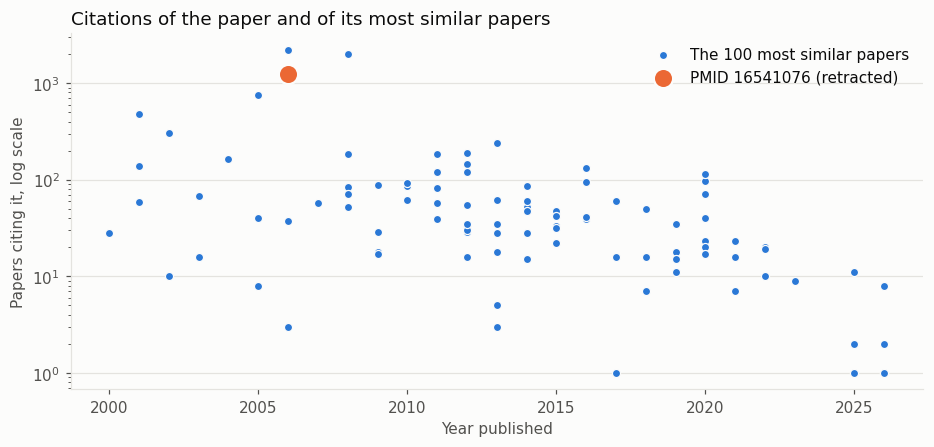

It is cited more than 98 of its 100 most similar papers; their median is 35 citations.


In [16]:
similar_citers = ci.citers_of([a.pmid for a in hood.similar])
similar = pd.DataFrame([{"pmid": a.pmid, "year": int(a.year), "citations": len(similar_citers.get(a.pmid, [])),
                         "title": a.title} for a in hood.similar if a.year and a.year.isdigit()])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(similar["year"], similar["citations"].clip(lower=1), s=28, color=tu.BLUE, edgecolor=tu.SURFACE, lw=0.8,
           label=f"The {len(similar)} most similar papers")
ax.scatter([first_year], [len(hop1)], s=160, color=tu.ORANGE, edgecolor=tu.SURFACE, lw=1.5,
           label=f"PMID {SEED} (retracted)")
ax.set_yscale("log")
tu.gridlines(ax)
ax.set_xlabel("Year published")
ax.set_ylabel("Papers citing it, log scale")
ax.legend(loc="upper right")
ax.set_title("Citations of the paper and of its most similar papers")
plt.show()
rank = (similar["citations"] > len(hop1)).sum() + 1
print(f"It is cited more than {len(similar) - rank + 1} of its {len(similar)} most similar papers; "
      f"their median is {similar['citations'].median():.0f} citations.")

## 9. A knowledge graph of the paper's impact

Everything above becomes an Obsidian knowledge graph in two steps:

1. The retracted paper's neighborhood: every paper citing it and the 100 most similar papers, each a note with its MeSH topics and flags.
2. The neighborhoods of some citing papers, their **neighbors' neighbors**: the retracted citing papers, then the most-cited papers that name Aβ\*56, up to `SECOND_HOP_SEEDS`, with 30 similar, citing and cited papers each.

Then each citing paper's note gets three properties of its own: `hop`, `citation_kind`, and `citation_sentence`, the sentence that cites the paper. Obsidian shows them on each note, and a table, **Citation impact.base**, lists the citing papers by kind. Rebuilding the graph keeps them.

In [17]:
TOPIC = "abeta56 retraction impact"
with tu.quiet():
    result = create_kg(TOPIC, seeds=[SEED], max_per_relation=5000)
    carriers = cited_by[cited_by["kind"] == f"Names {FINDING}"].nlargest(SECOND_HOP_SEEDS, "their_citers")
    second_seeds = list(dict.fromkeys(list(retracted["pmid"]) + list(carriers["pmid"])))[:SECOND_HOP_SEEDS]
    result = create_kg(TOPIC, seeds=second_seeds, max_per_relation=30)
print(result)

properties = {SEED: {"hop": 0}}
for row in cited_by.itertuples():
    sentence = row.sentence.replace(ci.CITE, f"[PMID {SEED}]")
    properties[row.pmid] = {"hop": 1, "citation_kind": row.kind, "citation_sentence": tu.short(sentence, 400)}
for pmid in hop2:
    properties.setdefault(pmid, {"hop": 2})
print("Notes annotated:", ci.annotate(result.kg_dir, properties))
print("Table:", ci.write_base(result.kg_dir).name)


Knowledge graph: abeta56 retraction impact
Folder:            workspace\retraction_impact\kg_abeta56_retraction_impact
Study searches:    0 (0 run now, 0 new articles)
Study seeds:       11 (10 fetched now)
Obsidian vault
Vault:             workspace\retraction_impact\kg_abeta56_retraction_impact
Sources:           11
Papers:            2008 (0 full text, 2008 stubs)
MeSH concepts:     2389
Collections:       11
Notes:             1134 created, 964 updated, 2311 unchanged
PubMed records:    86 fetched
  - Without MeSH:  278 (offline, too new, or a journal outside MEDLINE)


Notes annotated: 1682
Table: Citation impact.base


The citation network of the graph: the retracted paper in black at the centre, the papers citing it coloured by how they cite it, and the second-step papers small and pale. Retracted papers are ringed. Clusters are papers that cite each other, often one research group or one line of work.

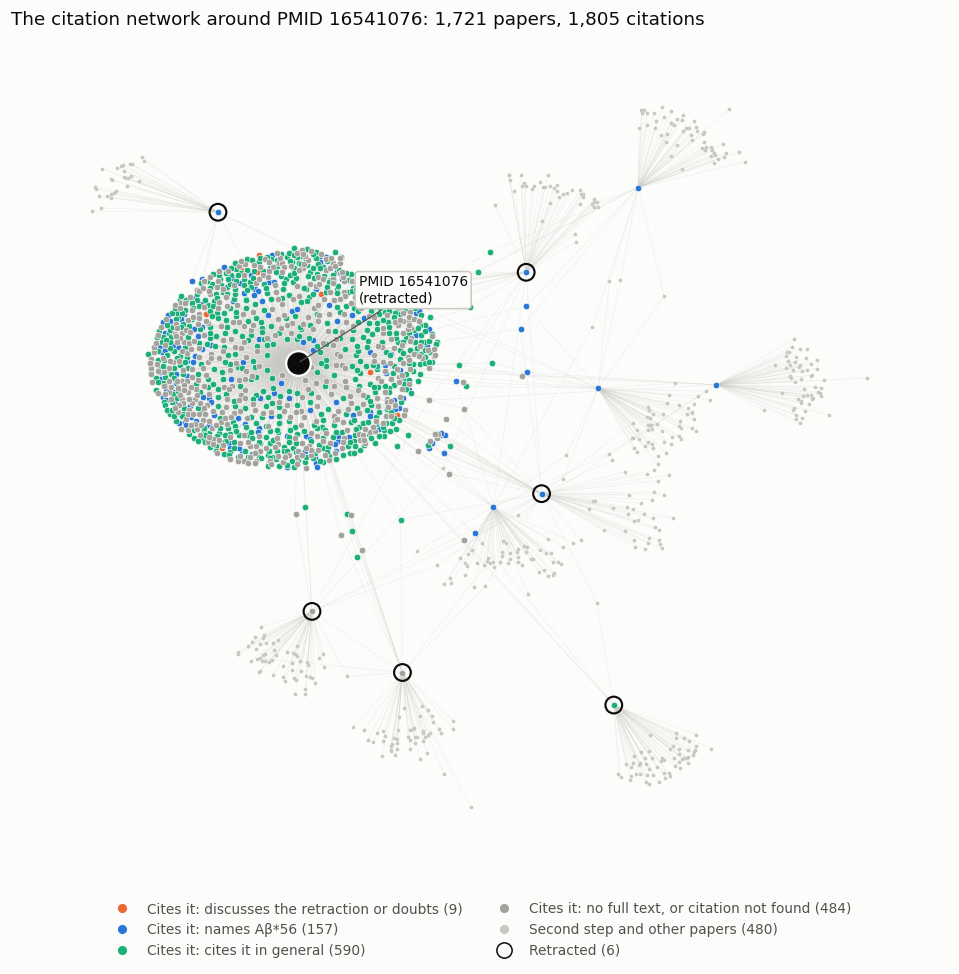

In [18]:
kg = tu.read_kg(result.kg_dir)
kinds = dict(zip(cited_by["pmid"], cited_by["kind"]))
fig, ax = plt.subplots(figsize=(11, 10))
graph = ci.draw_impact(kg, SEED, kinds, hop1, ax, KIND_COLOURS)
ax.set_title(f"The citation network around PMID {SEED}: {graph.number_of_nodes():,} papers, "
             f"{graph.number_of_edges():,} citations")
plt.show()

**Open it in Obsidian.** Choose **Open folder as vault** and select the folder printed above, `kg_abeta56_retraction_impact`; the [Obsidian guide](guides/obsidian.md) explains the rest. Then:

- Open **Citation impact** for the table of citing papers, one view per kind: you can read every citing sentence there, sort by year, and add your own columns.
- Open the retracted paper's note, `PMID16541076`, to see every paper citing it, and its retraction flag.
- Search `[citation_kind: "Discusses the retraction or doubts"]` to find the papers that discuss the retraction.

![The Citation impact table in Obsidian, showing the papers that discuss the retraction, with the sentence in which each one cites it](guides/images/obsidian-citation-impact.png)

In Google Colab, the next cell saves the graph to your computer as a zip file.

In [19]:
if tu.in_colab():
    tu.download(result.kg_dir)

## What the saved run found

The saved results come from a run on 18 October 2026; a new run finds slightly different numbers as papers are added.

- **Reach.** 1,240 papers in PubMed cite the retracted paper, and 44,921 more cite one of those. Together they include 15,039 of the 107,302 Alzheimer's disease papers in PubMed since 2006: one in seven. It is cited more than 98 of the 100 papers PubMed finds most similar to it.
- **Timing.** Citations peaked at 123 papers in 2012 and were falling well before doubts became public. The second step kept growing, to about 4,000 papers a year, after the retraction: the work built on the paper is still being built on.
- **Use.** Of the 756 citing papers whose citing sentence could be read, most cite the paper for a general statement about soluble amyloid-β oligomers and memory, and 578 never mention Aβ\*56 at all. 157 name Aβ\*56 where they cite it.
- **After the doubts.** 74 papers cite it from 2022 on, and 24 from 2024 on. Only 9 of them discuss the retraction or the doubts where they cite it; most of the rest cite it as before.
- **Retracted citing papers.** 6 papers citing it have been retracted themselves, and 4 of them list Lesné as an author.

## 10. What these numbers can and cannot tell you

- **The counts are PubMed's.** PubMed links a citation only when the citing article's full text is in PubMed Central, so it counts fewer citations than Google Scholar or Web of Science: 1,240 here, where nearly 2,500 have been reported for this paper. The shares and trends are more reliable than the totals.
- **The second step is an upper bound.** A paper two steps away may share nothing with Aβ\*56 beyond a common review. Section 7 shows how much of the reach passes through papers that name the finding.
- **The classification is by keywords.** "Controversy" may refer to the amyloid hypothesis in general rather than this paper, and a paper can discuss Aβ\*56 without the words in `FINDING_WORDS`. Read the sentences, in section 4 or in Obsidian, before you report a number.
- **A citation is not an endorsement.** Papers cite work to build on it, to compare with it, or to dispute it, and only the sentence tells which.
- **Retractions take time to spread.** PubMed marks the retracted paper, but citing papers written before the retraction stay as they are, and reviews keep their claims until they are revised.

To study another paper, change the settings at the top and run the notebook again. For a paper that has not been retracted, the same sections measure how its finding spread, and whether anyone has questioned it.

**Next:** [tutorial 4](04_evidence_neighborhood.ipynb) explains evidence neighborhoods, and [tutorial 5](05_knowledge_graph.ipynb) the knowledge graph, in more depth.